# 06 · Previsão das Próximas Quinzenas

O produto final do projeto: a previsão de vendas de cada loja × item para os
**30 dias seguintes ao fim dos dados**:
- **1ª quinzena:** 16/ago a 30/ago/2017
- **2ª quinzena:** 31/ago a 14/set/2017

**Como:**
1. Retreinamos os 30 modelos com cortes às **quartas-feiras** (o dia em que a previsão
   começa), usando os dados mais recentes — 12 cortes, de 26/abr a 12/jul;
2. Incorporamos as **promoções planejadas** de 16 a 31/ago (arquivo `test.csv` do Kaggle);
   para os dias seguintes, assumimos **sem promoção** (hipótese conservadora);
3. Aplicamos a **calibração por família** (validada no notebook 05), estimada no
   último corte de treino (12/jul).

## 1. Setup e carga
Carregamos todo o histórico de 2017, os cadastros e as promoções planejadas
para o período futuro (`test.csv`).

In [1]:
import sys
sys.path.append("..")

import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_processed, FAMILY_PT
from src.features import build_wide, build_dataset, N_HORIZONS
from src.models import national_holidays, train_direct, predict_saved
from src.calibration import fit_calibration, apply_calibration
from src.forecast import extend_promo, forecast_long

RAW = Path("../data/raw")
PROC = Path("../data/processed")
FIG = Path("../reports/figures")
MODELS_FINAL = Path("../models/final")
MODELS_FINAL.mkdir(parents=True, exist_ok=True)

data = load_processed()
train, items, stores = data["train_2017"], data["items"], data["stores"]
holidays = national_holidays(data["holidays"])
del data

test = pd.read_csv(RAW / "test.csv", usecols=["date", "store_nbr", "item_nbr", "onpromotion"],
                   parse_dates=["date"])
print(f"Histórico: {train['date'].min():%d/%m} a {train['date'].max():%d/%m/%Y}")
print(f"Promoções planejadas (test.csv): {test['date'].min():%d/%m} a {test['date'].max():%d/%m/%Y}")

Histórico: 01/01 a 15/08/2017
Promoções planejadas (test.csv): 16/08 a 31/08/2017


## 2. Matrizes de vendas e promoções futuras
Montamos a matriz loja × item × dia (como no notebook 03) e acrescentamos 30 colunas
futuras de promoção: os dias de 16 a 31/ago vêm do `test.csv`; os demais ficam em zero.
Itens que só aparecem no `test.csv` (lançamentos sem histórico) não são previstos.

In [2]:
FUTURE = pd.Timestamp("2017-08-16")

sales, promo = build_wide(train)
del train
promo = extend_promo(promo, test, FUTURE)

fut = promo.columns[promo.columns >= FUTURE]
print(f"Matriz: {sales.shape[0]:,} pares loja × item")
print(f"Promoções futuras: {fut.min():%d/%m} a {fut.max():%d/%m}")
print(f"% de pares em promoção — 1ª quinzena: {promo[fut[:15]].values.mean():.1%} | "
      f"2ª quinzena: {promo[fut[15:]].values.mean():.1%} (só 31/ago é conhecido)")

Matriz: 167,515 pares loja × item
Promoções futuras: 16/08 a 14/09
% de pares em promoção — 1ª quinzena: 7.1% | 2ª quinzena: 0.4% (só 31/ago é conhecido)


## 3. Cortes de treino (quartas-feiras)
12 quartas-feiras, de 26/abr a 12/jul. O último corte (12/jul) é reservado para o
*early stopping* e para estimar a calibração. Checagens: o histórico de 112 dias do
primeiro corte existe, e os alvos do último corte terminam dentro dos dados (10/ago).

In [4]:
train_cutoffs = pd.date_range("2017-04-26", "2017-07-12", freq="7D")
assert all(train_cutoffs.day_of_week == FUTURE.day_of_week), "Os cortes devem cair no mesmo dia da semana da previsão!"
assert train_cutoffs[0] - pd.Timedelta(days=112) >= sales.columns.min()
assert train_cutoffs[-1] + pd.Timedelta(days=N_HORIZONS - 1) <= sales.columns.max()

print(f"{len(train_cutoffs)} cortes ({train_cutoffs[0]:%A}):",
      ", ".join(d.strftime("%d/%m") for d in train_cutoffs))

df_train = build_dataset(sales, promo, train_cutoffs, items, stores)
df_future = build_dataset(sales, promo, [FUTURE], items, stores, with_target=False)
print(f"Treino: {df_train.shape[0]:,} linhas | Previsão futura: {df_future.shape[0]:,} pares loja × item")

12 cortes (Wednesday): 26/04, 03/05, 10/05, 17/05, 24/05, 31/05, 07/06, 14/06, 21/06, 28/06, 05/07, 12/07
Treino: 2,010,180 linhas | Previsão futura: 167,515 pares loja × item


## 4. Treino dos 30 modelos finais
Mesma estratégia e parâmetros do notebook 04, agora com mais dados (12 cortes).
Os modelos ficam em `models/final/`.

In [5]:
start = time.time()
fut_log, importance_final = train_direct(df_train, df_future, holidays, models_dir=MODELS_FINAL)
print(f"\nTempo total: {(time.time() - start) / 60:.1f} min")
np.save(PROC / "lgbm_future_preds.npy", fut_log)  # backup

h =  1 | árvores:  999 |  63.3 s
h =  2 | árvores:  727 |  67.3 s
h =  3 | árvores:  589 |  58.1 s
h =  4 | árvores:  843 |  97.0 s
h =  5 | árvores:  856 |  97.6 s
h =  6 | árvores:  575 |  73.5 s
h =  7 | árvores:  513 |  63.3 s
h =  8 | árvores:  866 | 100.8 s
h =  9 | árvores:  899 | 111.5 s
h = 10 | árvores:  747 |  95.1 s
h = 11 | árvores:  713 |  82.4 s
h = 12 | árvores:  102 |  27.0 s
h = 13 | árvores:  835 |  90.0 s
h = 14 | árvores:  576 |  53.4 s
h = 15 | árvores:  419 |  43.5 s
h = 16 | árvores:  494 |  49.4 s
h = 17 | árvores:  691 |  66.6 s
h = 18 | árvores:  647 |  60.7 s
h = 19 | árvores:  821 |  78.6 s
h = 20 | árvores:  654 |  69.8 s
h = 21 | árvores:  804 |  72.0 s
h = 22 | árvores:  983 |  81.9 s
h = 23 | árvores:  319 |  37.7 s
h = 24 | árvores:  998 |  83.5 s
h = 25 | árvores:  443 |  47.7 s
h = 26 | árvores:  350 |  40.7 s
h = 27 | árvores:  801 |  71.0 s
h = 28 | árvores:  990 |  81.0 s
h = 29 | árvores: 1000 |  82.7 s
h = 30 | árvores: 1000 |  81.2 s

Tempo tot

## 5. Calibração e montagem da previsão
Os fatores por família × quinzena são estimados no corte de 12/jul (não usado no treino)
e aplicados à previsão futura. Montamos a tabela final em **unidades**, com os segmentos
de negócio (família, tipo de loja, classe ABC calculada com todo o histórico).

In [6]:
fut_log = np.load(PROC / "lgbm_future_preds.npy")

df_cal = df_train[df_train["cutoff"] == train_cutoffs[-1]].reset_index(drop=True)
cal_preds = predict_saved(df_cal, holidays, MODELS_FINAL)
f_final = fit_calibration(df_cal, cal_preds, by="family")
fut_units = np.expm1(apply_calibration(df_future, fut_log, f_final, by="family"))

# Tabela final + segmentos
fam_names = dict(enumerate(items["family"].astype("category").cat.categories))
item_vol = (pd.Series(np.expm1(sales.to_numpy()).sum(axis=1), index=sales.index)
              .groupby(level="item_nbr").sum().sort_values(ascending=False))
abc = pd.cut(item_vol.cumsum() / item_vol.sum(), bins=[0, 0.80, 0.95, 1.01], labels=["A", "B", "C"])

prev = forecast_long(df_future, fut_units)
prev["family"] = prev["family"].map(fam_names).astype("category")
prev["store_type"] = prev["store_nbr"].map(stores.set_index("store_nbr")["type"]).astype("category")
prev["abc"] = prev["item_nbr"].map(abc.astype(str)).astype("category")
prev["quinzena"] = pd.Categorical(np.where(prev["h"] <= 15, "1ª quinzena (16–30/ago)",
                                           "2ª quinzena (31/ago–14/set)"))

prev.to_parquet(PROC / "previsao_futura.parquet", index=False)
f_final.rename(index=fam_names).to_parquet(PROC / "fatores_calibracao_final.parquet")
print(f"Previsão salva: {len(prev):,} linhas ({prev['date'].min():%d/%m} a {prev['date'].max():%d/%m/%Y})")
prev.groupby("quinzena", observed=True)["previsto"].sum().map("{:,.0f} unidades".format)

Previsão salva: 5,025,450 linhas (16/08 a 14/09/2017)


quinzena
1ª quinzena (16–30/ago)        11,336,555 unidades
2ª quinzena (31/ago–14/set)     9,951,214 unidades
Name: previsto, dtype: str

## 6. A previsão em perspectiva
Comparamos a previsão das próximas quinzenas com o histórico recente da rede e
destacamos as famílias com maior variação esperada.

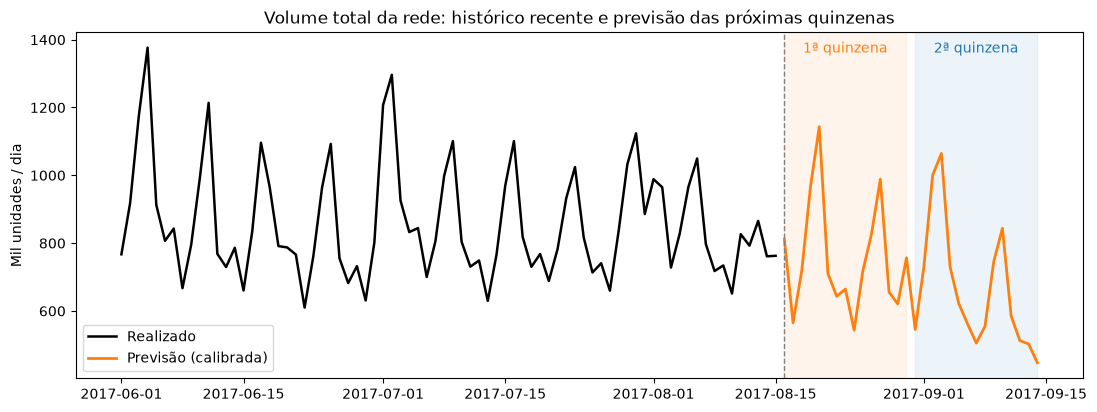

In [7]:
hist = pd.Series(np.expm1(sales.to_numpy()).sum(axis=0), index=sales.columns)
hist = hist[hist.index >= "2017-06-01"] / 1000
fut_daily = prev.groupby("date")["previsto"].sum() / 1000

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(hist.index, hist.values, color="black", lw=1.8, label="Realizado")
ax.plot(fut_daily.index, fut_daily.values, color="C1", lw=2, label="Previsão (calibrada)")
ax.axvspan(FUTURE, FUTURE + pd.Timedelta(days=14), color="C1", alpha=0.08)
ax.axvspan(FUTURE + pd.Timedelta(days=15), fut_daily.index.max(), color="C0", alpha=0.08)
ax.axvline(FUTURE, color="gray", ls="--", lw=1)
top = ax.get_ylim()[1]
ax.text(FUTURE + pd.Timedelta(days=7), top * 0.98, "1ª quinzena", ha="center", va="top", color="C1")
ax.text(FUTURE + pd.Timedelta(days=22), top * 0.98, "2ª quinzena", ha="center", va="top", color="C0")
ax.set(title="Volume total da rede: histórico recente e previsão das próximas quinzenas",
       ylabel="Mil unidades / dia")
ax.legend(loc="lower left")
plt.savefig(FIG / "06_previsao_futura.png", dpi=120, bbox_inches="tight")
plt.show()

In [8]:
# Referência: média diária dos últimos 30 dias (17/jul a 15/ago)
ult30 = sales.columns[-30:]
real30 = (pd.Series(np.expm1(sales[ult30].to_numpy()).sum(axis=1), index=sales.index)
            .groupby(level="item_nbr").sum())
real_fam = real30.groupby(real30.index.map(items.set_index("item_nbr")["family"])).sum() / 30

tab = prev.pivot_table(index="family", columns="quinzena", values="previsto",
                       aggfunc="sum", observed=True) / 15
tab.columns = ["1ª quinzena (unid./dia)", "2ª quinzena (unid./dia)"]
tab["Últimos 30 dias (unid./dia)"] = real_fam.reindex(tab.index)
tab["Variação 1ª quinz."] = tab.iloc[:, 0] / tab["Últimos 30 dias (unid./dia)"] - 1
tab["Variação 2ª quinz."] = tab.iloc[:, 1] / tab["Últimos 30 dias (unid./dia)"] - 1
tab = tab.sort_values("1ª quinzena (unid./dia)", ascending=False).head(15)

tab.style.format({c: "{:,.0f}" for c in tab.columns[:3]} |
                 {"Variação 1ª quinz.": "{:+.1%}", "Variação 2ª quinz.": "{:+.1%}"}
).format_index(lambda f: f"{f}<br><small style='color:gray'>{FAMILY_PT.get(f, '')}</small>", axis=0)

,1ª quinzena (unid./dia),2ª quinzena (unid./dia),Últimos 30 dias (unid./dia),Variação 1ª quinz.,Variação 2ª quinz.
family,,,,,
GROCERY IMercearia I,"221,544","231,273","245,323",-9.7%,-5.7%
BEVERAGESBebidas,"185,890","184,730","190,515",-2.4%,-3.0%
PRODUCEHortifrúti,"99,804","28,553","123,660",-19.3%,-76.9%
CLEANINGLimpeza,"60,294","70,822","68,563",-12.1%,+3.3%
DAIRYLaticínios,"41,727","38,056","45,250",-7.8%,-15.9%
BREAD/BAKERYPadaria,"27,007","24,054","28,749",-6.1%,-16.3%
PERSONAL CAREHigiene pessoal,"17,138","15,739","16,987",+0.9%,-7.3%
MEATSCarnes,"16,763","7,941","20,173",-16.9%,-60.6%
HOME CARECuidados com a casa,"15,764","15,275","16,481",-4.4%,-7.3%


## 7. Diagnóstico: o efeito da hipótese "sem promoção"
A primeira versão da previsão mostrou a 2ª quinzena **20% abaixo** do histórico recente —
mesmo incluindo o início de setembro (pico de pagamento). Suspeita: ao assumir **nenhuma
promoção** de 01 a 14/set, zeramos `promo_target` e `promo_next_16_30` para todos os itens.
No treino, "zero promoções planejadas" era típico de itens de **baixo giro** — uma
**mudança de distribuição** entre treino e previsão.

**Cenário alternativo:** para os dias sem informação, repetir o calendário promocional de
**14 dias antes** (mesmo dia da semana). Os modelos são os mesmos; só refazemos a previsão.

In [9]:
# Recarrega o forecast.py atualizado
import importlib, src.forecast
importlib.reload(src.forecast)
from src.forecast import extend_promo, forecast_long

# Promoções futuras no cenário "repetir 14 dias antes"
promo_hist = promo.loc[:, promo.columns < FUTURE]
promo_rep = extend_promo(promo_hist, test, FUTURE, fill_unknown="repeat")
fut = promo_rep.columns[promo_rep.columns >= FUTURE]
print(f"% de pares em promoção — 1ª quinzena: {promo_rep[fut[:15]].values.mean():.1%} | "
      f"2ª quinzena: {promo_rep[fut[15:]].values.mean():.1%}")

# Nova previsão com os MESMOS modelos e a MESMA calibração
df_future_rep = build_dataset(sales, promo_rep, [FUTURE], items, stores, with_target=False)
fut_log_rep = predict_saved(df_future_rep, holidays, MODELS_FINAL)
units_rep = np.expm1(apply_calibration(df_future_rep, fut_log_rep, f_final, by="family"))

# Comparação dos cenários
q1 = np.arange(1, N_HORIZONS + 1) <= 15
ref = np.expm1(sales.iloc[:, -30:].to_numpy()).sum() / 2   # média quinzenal dos últimos 30 dias
comp = pd.DataFrame({
    "Sem promoção em set.": [fut_units[:, q1].sum(), fut_units[:, ~q1].sum()],
    "Promoções repetidas": [units_rep[:, q1].sum(), units_rep[:, ~q1].sum()],
}, index=["1ª quinzena (16–30/ago)", "2ª quinzena (31/ago–14/set)"])
comp["Efeito do cenário"] = comp["Promoções repetidas"] / comp["Sem promoção em set."] - 1
comp["vs. média quinzenal recente"] = comp["Promoções repetidas"] / ref - 1
comp.style.format({"Sem promoção em set.": "{:,.0f}", "Promoções repetidas": "{:,.0f}",
                   "Efeito do cenário": "{:+.1%}", "vs. média quinzenal recente": "{:+.1%}"})

% de pares em promoção — 1ª quinzena: 7.1% | 2ª quinzena: 6.8%


,Sem promoção em set.,Promoções repetidas,Efeito do cenário,vs. média quinzenal recente
1ª quinzena (16–30/ago),"11,336,555","11,917,398",+5.1%,-4.6%
2ª quinzena (31/ago–14/set),"9,951,214","12,784,610",+28.5%,+2.3%


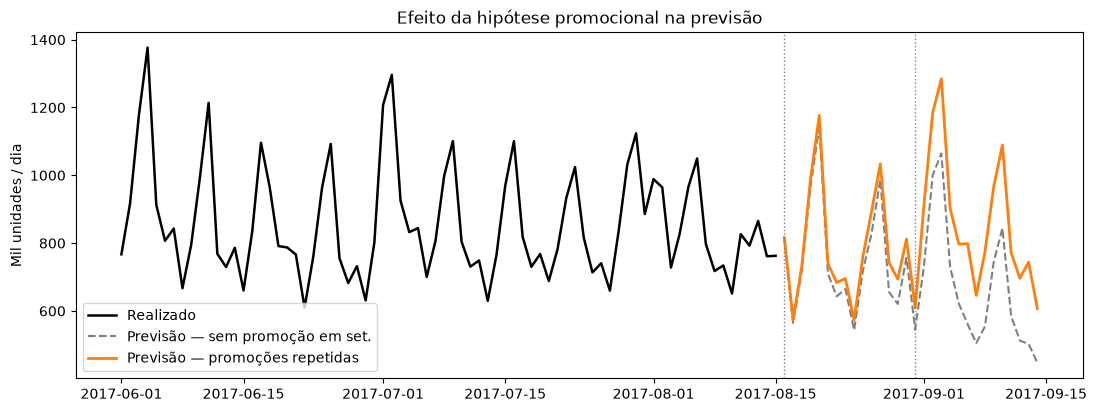

In [10]:
dates_fut = pd.date_range(FUTURE, periods=N_HORIZONS)
hist = pd.Series(np.expm1(sales.to_numpy()).sum(axis=0), index=sales.columns)
hist = hist[hist.index >= "2017-06-01"] / 1000

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(hist.index, hist.values, color="black", lw=1.8, label="Realizado")
ax.plot(dates_fut, fut_units.sum(axis=0) / 1000, color="gray", ls="--", label="Previsão — sem promoção em set.")
ax.plot(dates_fut, units_rep.sum(axis=0) / 1000, color="C1", lw=2, label="Previsão — promoções repetidas")
ax.axvline(FUTURE, color="gray", ls=":", lw=1)
ax.axvline(FUTURE + pd.Timedelta(days=15), color="gray", ls=":", lw=1)
ax.set(title="Efeito da hipótese promocional na previsão", ylabel="Mil unidades / dia")
ax.legend(loc="lower left")
plt.savefig(FIG / "06_cenario_promocional.png", dpi=120, bbox_inches="tight")
plt.show()

### 💡 Insights — Diagnóstico confirmado

| | Sem promoção em set. | Promoções repetidas | vs. média recente |
|---|---|---|---|
| 1ª quinzena (16–30/ago) | 11,34 mi | **11,92 mi** | −4,6% |
| 2ª quinzena (31/ago–14/set) | 9,95 mi | **12,78 mi** | +2,3% |

1. **A hipótese "sem promoção" derrubava a previsão em 28,5% na 2ª quinzena** — não
   por falta de promoções em si, mas porque o modelo associa "zero promoções planejadas"
   a itens de baixo giro (**mudança de distribuição** entre treino e previsão).
2. **Prova do diagnóstico:** a 1ª quinzena também subiu (+5,1%) sem nenhuma mudança nas
   suas promoções — o efeito vinha da feature `promo_next_16_30`, usada por todos os modelos.
3. **O cenário corrigido é coerente com a EDA:** a 2ª quinzena (com o início de setembro)
   fica **7,2% acima** da 1ª — a EDA mostrou ~6% a mais na primeira metade do mês
   (efeito do pagamento). A 1ª quinzena (16–30/ago, fim de mês) fica 4,6% abaixo da
   média recente, também como esperado.

**Lições**
- **Toda previsão precisa de uma checagem de sanidade** contra o histórico antes de
  ser entregue — o erro não aparecia em nenhuma métrica, só no gráfico.
- **Hipóteses sobre o futuro importam:** o calendário promocional deve ser informado
  pela área comercial. Quando ele não existe, repetir o padrão recente é muito mais
  seguro do que assumir "nenhuma promoção".
- **Melhoria futura:** treinar os modelos sem as features de promoção da 2ª quinzena,
  ou com uma versão "conhecida até o dia X", para reduzir a dependência dessa informação.

> ⚠️ **Versão preliminar** (cenário "sem promoção em setembro"). A análise da seção 7
> mostrou que essa hipótese distorce a previsão; a versão oficial está na seção 8.

## 8. Previsão oficial (cenário "promoções repetidas")
Substituímos a previsão salva pela versão corrigida, que alimentará o painel.

In [11]:
# Monta e salva a previsão oficial
prev = forecast_long(df_future_rep, units_rep)
prev["family"] = prev["family"].map(fam_names).astype("category")
prev["store_type"] = prev["store_nbr"].map(stores.set_index("store_nbr")["type"]).astype("category")
prev["abc"] = prev["item_nbr"].map(abc.astype(str)).astype("category")
prev["quinzena"] = pd.Categorical(np.where(prev["h"] <= 15, "1ª quinzena (16–30/ago)",
                                           "2ª quinzena (31/ago–14/set)"))
prev.to_parquet(PROC / "previsao_futura.parquet", index=False)
print(f"Previsão oficial salva: {len(prev):,} linhas")
prev.groupby("quinzena", observed=True)["previsto"].sum().map("{:,.0f} unidades".format)

Previsão oficial salva: 5,025,450 linhas


quinzena
1ª quinzena (16–30/ago)        11,917,398 unidades
2ª quinzena (31/ago–14/set)    12,784,610 unidades
Name: previsto, dtype: str

In [12]:
# Referência: média diária dos últimos 30 dias (17/jul a 15/ago), por família
ult30 = sales.columns[-30:]
real30 = (pd.Series(np.expm1(sales[ult30].to_numpy()).sum(axis=1), index=sales.index)
            .groupby(level="item_nbr").sum())
real_fam = real30.groupby(real30.index.map(items.set_index("item_nbr")["family"])).sum() / 30

tab = prev.pivot_table(index="family", columns="quinzena", values="previsto",
                       aggfunc="sum", observed=True) / 15
tab.columns = ["1ª quinzena (unid./dia)", "2ª quinzena (unid./dia)"]
tab["Últimos 30 dias (unid./dia)"] = real_fam.reindex(tab.index)
tab["Variação 1ª quinz."] = tab.iloc[:, 0] / tab["Últimos 30 dias (unid./dia)"] - 1
tab["Variação 2ª quinz."] = tab.iloc[:, 1] / tab["Últimos 30 dias (unid./dia)"] - 1
tab = tab.sort_values("1ª quinzena (unid./dia)", ascending=False).head(15)

tab.style.format({c: "{:,.0f}" for c in tab.columns[:3]} |
                 {"Variação 1ª quinz.": "{:+.1%}", "Variação 2ª quinz.": "{:+.1%}"}
).format_index(lambda f: f"{f}<br><small style='color:gray'>{FAMILY_PT.get(f, '')}</small>", axis=0)

,1ª quinzena (unid./dia),2ª quinzena (unid./dia),Últimos 30 dias (unid./dia),Variação 1ª quinz.,Variação 2ª quinz.
family,,,,,
GROCERY IMercearia I,"223,987","249,956","245,323",-8.7%,+1.9%
BEVERAGESBebidas,"188,181","198,636","190,515",-1.2%,+4.3%
PRODUCEHortifrúti,"121,443","118,876","123,660",-1.8%,-3.9%
CLEANINGLimpeza,"60,714","75,921","68,563",-11.4%,+10.7%
DAIRYLaticínios,"42,471","44,502","45,250",-6.1%,-1.7%
BREAD/BAKERYPadaria,"27,585","28,341","28,749",-4.0%,-1.4%
MEATSCarnes,"20,226","21,046","20,173",+0.3%,+4.3%
POULTRYAves,"19,467","20,208","20,442",-4.8%,-1.1%
PERSONAL CAREHigiene pessoal,"17,351","18,323","16,987",+2.1%,+7.9%


> ⚠️ **Atenção à interpretação:** a diferença de +28,5% entre os cenários **não** mede o
> efeito das promoções nas vendas — ela reflete como o modelo interpreta "zero promoções
> planejadas" (padrão típico de itens de baixo giro). Pelos dados da EDA, as promoções
> respondem por ~19% do volume com uplift mediano de +33%, o que indica um efeito real
> da ordem de **~5% do volume total**. Avaliar se uma promoção **vale a pena** exigiria
> dados de preço, desconto e margem, que não estão disponíveis neste dataset.
>
> **Recomendação:** integrar o **calendário promocional** da área comercial ao processo
> de previsão, com pelo menos 30 dias de antecedência.

### 💡 Insights — Previsão oficial das próximas quinzenas

| Quinzena | Previsão | Média diária | vs. média quinzenal recente |
|---|---|---|---|
| **1ª (16–30/ago)** | **11,9 milhões** de unidades | ~794 mil/dia | −4,6% |
| **2ª (31/ago–14/set)** | **12,8 milhões** de unidades | ~852 mil/dia | +2,3% |

**O que a previsão mostra**
1. **Itens de "compra do mês" oscilam com o pagamento:** caem no fim de agosto e
   sobem com o início de setembro.
   | Família | 1ª quinzena | 2ª quinzena | Oscilação |
   |---|---|---|---|
   | CLEANING <small>(limpeza)</small> | −11,4% | **+10,7%** | 22 p.p. |
   | GROCERY I <small>(mercearia)</small> | −8,7% | +1,9% | 11 p.p. |
   | DELI <small>(frios e embutidos)</small> | −6,2% | +5,3% | 12 p.p. |
   | PERSONAL CARE <small>(higiene pessoal)</small> | +2,1% | **+7,9%** | 6 p.p. |
2. **Perecíveis são estáveis — compra diária, pouco sensível ao pagamento:**
   PRODUCE <small>(hortifrúti)</small> −1,8% / −3,9%, BREAD/BAKERY <small>(padaria)</small>
   −4,0% / −1,4%, POULTRY <small>(aves)</small> −4,8% / −1,1%, EGGS <small>(ovos)</small>
   −2,2% / +2,3%.
3. **BEVERAGES** <small>(bebidas)</small>, a 2ª maior família, fica estável na 1ª quinzena
   (−1,2%) e sobe na 2ª (+4,3%).

**Decisões de compra e reposição**
- **1ª quinzena (16–30/ago) — segurar compras de não perecíveis:** reduzir pedidos de
  limpeza (~−11%) e mercearia (~−9%) em relação ao ritmo recente, evitando estoque
  parado no fim do mês.
- **2ª quinzena (31/ago–14/set) — antecipar o pico de setembro:** pedidos de limpeza
  (+11%), higiene pessoal (+8%) e frios (+5%) devem **chegar às lojas até 31/ago**,
  antes do fim de semana pós-pagamento (02–03/set), o maior pico previsto.
- **Perecíveis — manter o ritmo atual**, com leve redução em hortifrúti na 2ª quinzena.

**Ajustes recomendados pelo histórico de erro (notebook 05)**
- **Bebidas e limpeza** foram **subestimadas em ~10%** na validação → manter estoque
  de segurança ~10% acima da previsão nessas famílias.
- **Comida pronta** foi **superestimada em ~9%** → pedir abaixo da previsão: é
  perecível de vida curta e o excesso vira perda.
- **Lojas tipo C** (menores) foram subestimadas em ~12% → reforçar a margem de segurança.

> ⚠️ **Premissas:** promoções de 16–31/ago conforme o calendário do `test.csv`; para
> 01–14/set, repetição do calendário de 14 dias antes. Erro esperado no total quinzenal
> por loja × item: ~27–33% (validação); no agregado por família ou rede, o erro é
> bem menor.